Importing Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import jit
from scipy import interpolate
from scipy.optimize import minimize

In [2]:
@jit(nopython=True)
def Pressure(n_list, K, Gam):
    p = K*(n_list)**(Gam)
    return p

@jit(nopython=True)
def chemical_potential(n_list, K, Gam, m0):
    t1 = ((K*Gam)/(Gam - 1))*((n_list)**(Gam - 1))
    re = t1 + m0
    return re

@jit(nopython=True)
def energy_density(n_list, K, Gam, m0):
    t1 = (K * ((n_list) ** Gam)) / (Gam - 1)
    t2 = t1 + (m0 * (n_list))
    return t2

constructing EoS :

In [3]:
# Initial Values :

n_had =np.linspace(0.16,0.32,1000)
Gam_had = 4.921
K_had = 17906.60
m0_had = 939.56

pressure_transition = 63.177
energy_density_transition = 318.26
energy_density_transition_jump = 253.89
energy_density_quark = energy_density_transition + energy_density_transition_jump

n_quark = np.linspace(0.5344,1,1000)
Gam_quark = 2.5
K_quark = pressure_transition / (n_quark[0] ** Gam_quark)
m0_quark = (energy_density_quark - (K_quark * (n_quark[0] ** Gam_quark)) / (Gam_quark - 1)) / n_quark[0]

n_total = np.linspace(0.16,1,2000)

EoS Hadronic

In [4]:
pressure_had = Pressure(n_total, K_had, Gam_had)
chemical_potential_had = chemical_potential(n_total, K_had, Gam_had, m0_had)
energy_density_had = energy_density(n_total, K_had, Gam_had, m0_had)

EoS Quark

In [5]:
pressure_quark = Pressure(n_total, K_quark, Gam_quark)
chemical_potential_quark = chemical_potential(n_total, K_quark, Gam_quark, m0_quark)
energy_density_quark = energy_density(n_total, K_quark, Gam_quark, m0_quark)

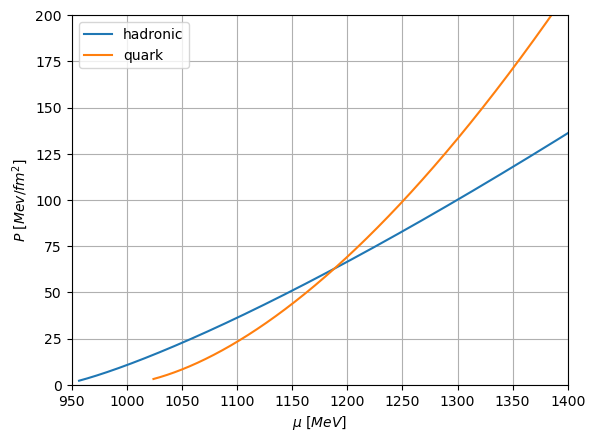

In [6]:
plt.plot(chemical_potential_had, pressure_had, label = "hadronic")
plt.plot(chemical_potential_quark,pressure_quark, label = "quark")

plt.xlim([950,1400])
plt.ylim([0,200])
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.grid()

In [7]:
mu_quark_new = []
for i in range(100):
    mu_quark_0 = (chemical_potential_quark - 50 + i)
    mu_quark_new.append(mu_quark_0)

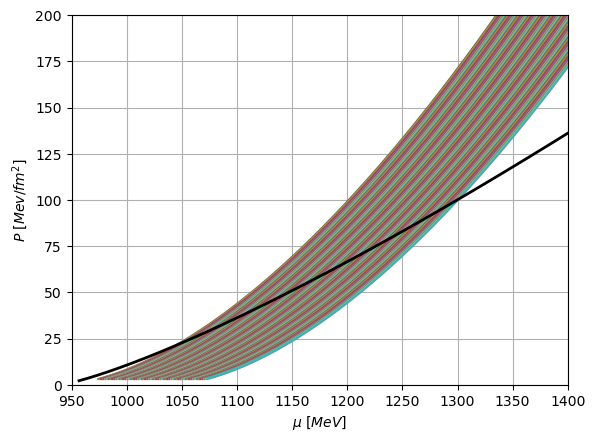

In [8]:
for i in range(len(mu_quark_new)):  # Assuming mu_quark_new is a list of lists
    plt.plot(mu_quark_new[i], pressure_quark, label=f"quark set {i+1}")

plt.plot(chemical_potential_had, pressure_had, label="hadronic", color='black', linewidth=2)  # Hadronic plot
plt.xlim([950, 1400])
plt.ylim([0, 200])
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
#plt.legend(loc='upper right', bbox_to_anchor=(1.15, 1))  # Adjust legend position to handle many labels
plt.grid()
plt.show()

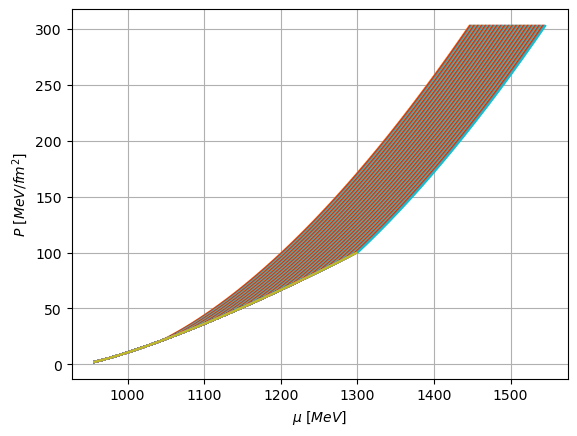

In [9]:
x1 = np.array(chemical_potential_had)
y1 = np.array(pressure_had)

# Interpolate the hadronic phase data
P_h_int_func = interpolate.interp1d(x1, y1)

# List to store combined curves for each quark phase
combined_mu_curves_quark, combined_mu_curves_had = [], []
combined_P_curves_quark, combined_P_curves_had = [], []
P_crit = []
mu_crit = []

combined_mu_curves, combined_p_curves = [], []
index_points =[]

# Loop over all the mu_quark sets in mu_quark_new
for i, mu_quark_set in enumerate(mu_quark_new):
    x2 = np.array(mu_quark_set)
    y2 = np.array(pressure_quark)  # Assuming P_3_all is the same for all quark sets

    # Generate a new mu array for interpolation
    mu_new = np.linspace(min(mu_quark_set), 1400, 1000)
    P_had_array = P_h_int_func(mu_new)

    # Interpolate quark phase data
    P_q_int_func = interpolate.interp1d(x2, y2)
    P_quark_array = P_q_int_func(mu_new)

    # Calculate the difference between hadronic and quark phases
    y_diff = np.abs(P_had_array - P_quark_array)
    index_intersect = np.argmin(y_diff)  # Approximate intersection index in the interpolated array

    # Get the approximate intersection point
    x_intersect = mu_new[index_intersect]

    # Find the closest index in the original arrays to this intersection point
    index_had_closest = (np.abs(x1 - x_intersect)).argmin()
    index_quark_closest = (np.abs(x2 - x_intersect)).argmin()

    index_points.append(index_had_closest)

    # Slice the original arrays at the closest intersection points
    mu_had_1 = x1[:index_had_closest]
    P_had = y1[:index_had_closest]
    mu_quark_2 = x2[index_quark_closest:]
    P_quark_2 = y2[index_quark_closest:]

    P_crit.append(P_quark_2[0])
    mu_crit.append(mu_quark_2[0])

    # Combine the original arrays at the intersection point
    combined_mu = np.concatenate((mu_had_1, mu_quark_2))
    combined_P = np.concatenate((P_had, P_quark_2))

    combined_mu_curves.append(combined_mu)
    combined_p_curves.append(combined_P)

    # Store the combined curves in the list
    combined_mu_curves_quark.append(mu_quark_2)
    combined_P_curves_quark.append(P_quark_2)

    # Store the combined curves in the list
    combined_mu_curves_had.append(mu_had_1)
    combined_P_curves_had.append(P_had)

# Plot the combined curves
for i in range(len(combined_mu_curves_had)):
    plt.plot(combined_mu_curves_had[i], combined_P_curves_had[i], label=f"Combined Curve {i+1}")
    plt.plot(combined_mu_curves_quark[i], combined_P_curves_quark[i], label=f"Combined Curve {i+1}")

# Final plot settings
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [MeV/fm^2]$")
# plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1))  # Uncomment if legend is needed
plt.grid()
plt.show()


In [10]:
def gradient(n, m):
    
    if len(n) != len(m):
        raise ValueError("n and m must have the same length.")
    
    gradients = []
    for i in range(len(n) - 1):  # Loop up to the second-to-last element
        grad = (n[i + 1] - n[i]) / (m[i + 1] - m[i])
        gradients.append(grad)
    
    return gradients

In [11]:
combined_n = []
combined_e = []
combined_cs2 = []
combined_p_1, combined_mu_1 = [], []
combined_cs2_11 = []
# Loop over each combined curve to calculate the gradient
for i in range(len(combined_P_curves_had)):
    P_curve_1 = combined_P_curves_had[i]
    mu_curve_1 = combined_mu_curves_had[i]

    P_curve_2 = combined_P_curves_quark[i]
    mu_curve_2 = combined_mu_curves_quark[i]

    # Compute the gradient of P with respect to mu
    gradient_1 = np.gradient(P_curve_1, mu_curve_1)
    gradient_2 = np.gradient(P_curve_2, mu_curve_2)

    e_curve_1 = (gradient_1*mu_curve_1)-P_curve_1
    cs2_1 = np.gradient(P_curve_1,e_curve_1)

    e_curve_2 = (gradient_2*mu_curve_2)-P_curve_2
    cs2_2 = np.gradient(P_curve_2,e_curve_2)

    P_curve_22 = np.linspace(P_curve_1[-1],P_curve_1[-1],10)
    mu_curve_22 = np.linspace(mu_curve_1[-1],mu_curve_1[-1],10)
    e_curve_22 = np.linspace(e_curve_1[-1],e_curve_2[0],10)
    cs2_22 = np.gradient(P_curve_22,e_curve_22)

    combined_n.append(np.concatenate((gradient_1,gradient_2)))
    combined_e.append(np.concatenate((e_curve_1,e_curve_22,e_curve_2)))
    combined_cs2.append(np.concatenate((cs2_1,cs2_22,cs2_2)))
    combined_p_1.append(np.concatenate((P_curve_1,P_curve_22,P_curve_2)))
    combined_mu_1.append(np.concatenate((mu_curve_1,mu_curve_22,mu_curve_2)))


    cs2_11 = np.gradient(np.concatenate((P_curve_1,P_curve_22,P_curve_2)),np.concatenate((e_curve_1,e_curve_22,e_curve_2)))
    combined_cs2_11.append(cs2_11)


/opt/anaconda3/envs/myenv1/lib/python3.12/site-packages/numpy/lib/function_base.py:1242: RuntimeWarning: divide by zero encountered in divide
  a = -(dx2)/(dx1 * (dx1 + dx2))
/opt/anaconda3/envs/myenv1/lib/python3.12/site-packages/numpy/lib/function_base.py:1243: RuntimeWarning: divide by zero encountered in divide
  b = (dx2 - dx1) / (dx1 * dx2)
/opt/anaconda3/envs/myenv1/lib/python3.12/site-packages/numpy/lib/function_base.py:1244: RuntimeWarning: divide by zero encountered in divide
  c = dx1 / (dx2 * (dx1 + dx2))
/opt/anaconda3/envs/myenv1/lib/python3.12/site-packages/numpy/lib/function_base.py:1250: RuntimeWarning: invalid value encountered in add
  out[tuple(slice1)] = a * f[tuple(slice2)] + b * f[tuple(slice3)] + c * f[tuple(slice4)]


In [12]:
combined_n = []
combined_e = []
combined_cs2 = []
combined_p_1, combined_mu_1 = [], []

# Loop over each combined curve to calculate the gradient
for i in range(len(combined_P_curves_had)):
    P_curve_1 = combined_P_curves_had[i]
    mu_curve_1 = combined_mu_curves_had[i]

    P_curve_2 = combined_P_curves_quark[i]
    mu_curve_2 = combined_mu_curves_quark[i]

    P_11 = np.concatenate((P_curve_1,P_curve_2))
    mu_11 = np.concatenate((mu_curve_1,mu_curve_2))

    gradient_11 = gradient(P_11, mu_11)
    e_11 = (gradient_11*mu_11[:-1])-P_11[:-1]
    combined_cs2.append(gradient(P_11[:-1],e_11))
    combined_n.append(gradient_11)
    combined_e.append(e_11)
    combined_p_1.append(P_11)
    combined_mu_1.append(mu_11)



def pop_11(combined_p_1, combined_mu_1,combined_cs2,combined_e,n):
    for i in range(len(combined_cs2)):
        combined_mu_1[i]=np.delete(combined_mu_1[i],index_points[i]-n)
        combined_e[i]=np.delete(combined_e[i],index_points[i]-n)
        combined_p_1[i]=np.delete(combined_p_1[i],index_points[i]-n)
        combined_cs2[i]=np.delete(combined_cs2[i],index_points[i]-n)
    return()
    


In [13]:
pop_11(combined_p_1, combined_mu_1,combined_cs2,combined_e,2)

()

In [14]:
pop_11(combined_p_1, combined_mu_1,combined_cs2,combined_e,2)

()

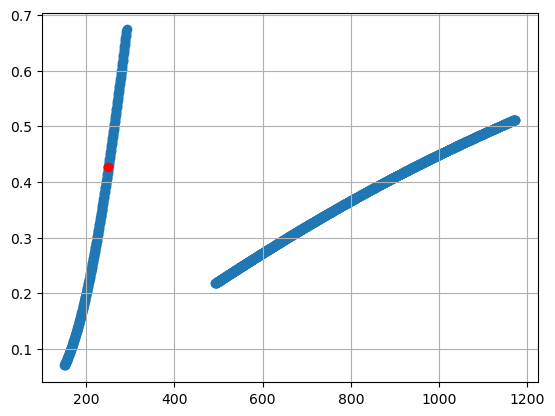

In [15]:
plt.scatter(combined_e[30][:-1],combined_cs2[30])
plt.scatter(combined_e[30][:-1][238],combined_cs2[30][238],color = 'red')
plt.grid()
plt.show()

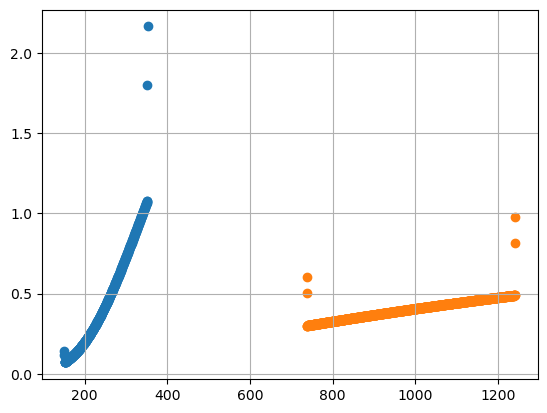

In [16]:
plt.scatter(e_curve_1,cs2_1)
plt.scatter(e_curve_2,cs2_2)
plt.grid()
plt.show()

In [17]:
mu_curve_1[-1]

1298.8498404772072

In [18]:
mu_curve_2[0]

1301.2786849161625

In [19]:
plt.scatter(mu_total[30],p_total[30]);
plt.grid()
plt.xlabel(r"$\epsilon \ [Mev/fm^2]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.show();

NameError: name 'mu_total' is not defined

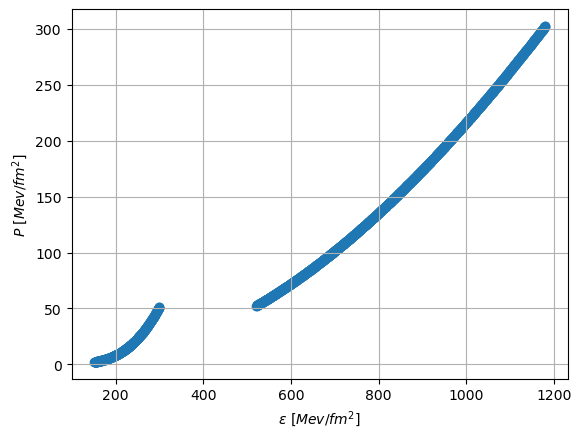

In [20]:
plt.scatter(combined_e[37],combined_p_1[37][:-1]);
plt.grid()
plt.xlabel(r"$\epsilon \ [Mev/fm^2]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.show();

In [21]:
e_total, p_total, mu_total, cs_total = combined_e, combined_p_1, combined_mu_1, combined_cs2

In [22]:
e_total

[array([ 151.08430517,  151.48634409,  151.88845752, ..., 1142.05196167,
        1142.65939714, 1143.26696617]),
 array([ 151.08430517,  151.48634409,  151.88845752, ..., 1143.05091115,
        1143.65876684, 1144.26675607]),
 array([ 151.08430517,  151.48634409,  151.88845752, ..., 1144.04986063,
        1144.65813653, 1145.26654597]),
 array([ 151.08430517,  151.48634409,  151.88845752, ..., 1145.04881011,
        1145.65750622, 1146.26633587]),
 array([ 151.08430517,  151.48634409,  151.88845752, ..., 1146.0477596 ,
        1146.65687591, 1147.26612578]),
 array([ 151.08430517,  151.48634409,  151.88845752, ..., 1147.04670908,
        1147.6562456 , 1148.26591568]),
 array([ 151.08430517,  151.48634409,  151.88845752, ..., 1148.04565856,
        1148.6556153 , 1149.26570558]),
 array([ 151.08430517,  151.48634409,  151.88845752, ..., 1149.04460804,
        1149.65498499, 1150.26549548]),
 array([ 151.08430517,  151.48634409,  151.88845752, ..., 1150.04355753,
        1150.65435468, 

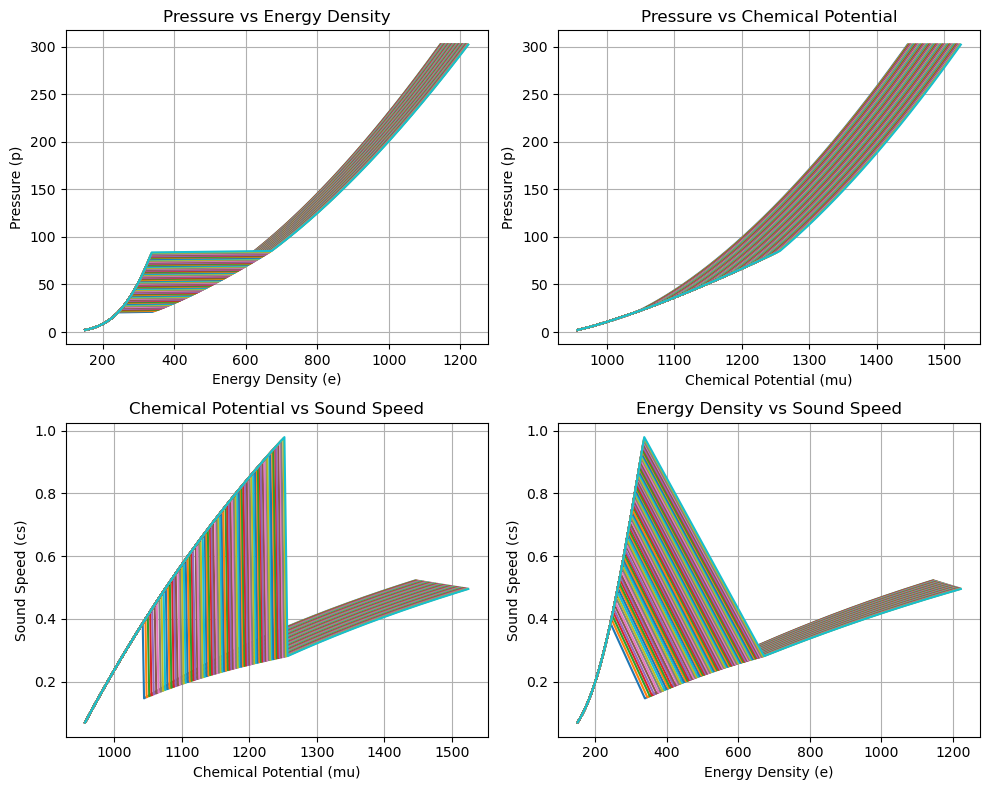

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for i in range(len(p_total)-20):
    # Plot 1: Pressure vs Energy Density
    axes[0, 0].plot(e_total[i], p_total[i][:-1])

    # Plot 2: Pressure vs Chemical Potential
    axes[0, 1].plot(mu_total[i][:-1], p_total[i][:-1])

    # Plot 3: Chemical Potential vs Sound Speed
    axes[1, 0].plot(mu_total[i][:-2], cs_total[i])

    # Plot 4: Energy Density vs Sound Speed
    axes[1, 1].plot(e_total[i][:-1], cs_total[i])

# Adding titles, labels, and legends after the loop

# Plot 1: Pressure vs Energy Density
axes[0, 0].set_title('Pressure vs Energy Density')
axes[0, 0].set_xlabel('Energy Density (e)')
axes[0, 0].set_ylabel('Pressure (p)')
axes[0, 0].grid(True)
#axes[0, 0].legend()

# Plot 2: Pressure vs Chemical Potential
axes[0, 1].set_title('Pressure vs Chemical Potential')
axes[0, 1].set_xlabel('Chemical Potential (mu)')
axes[0, 1].set_ylabel('Pressure (p)')
axes[0, 1].grid(True)
#axes[0, 1].legend()

# Plot 3: Chemical Potential vs Sound Speed
axes[1, 0].set_title('Chemical Potential vs Sound Speed')
axes[1, 0].set_ylabel('Sound Speed (cs)')
axes[1, 0].set_xlabel('Chemical Potential (mu)')
axes[1, 0].grid(True)
#axes[1, 0].legend()

# Plot 4: Energy Density vs Sound Speed
axes[1, 1].set_title('Energy Density vs Sound Speed')
axes[1, 1].set_ylabel('Sound Speed (cs)')
axes[1, 1].set_xlabel('Energy Density (e)')
axes[1, 1].grid(True)
#axes[1, 1].legend()

# Adjust spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()

In [28]:
P_all = []
P_all_1 = []
P_max_points = []
P_max_points_1 = []
delta_P_Points = []
delta_P_optimal_max = []

P_all_max = []
# Iterate through each mu_total and p_total index
for index in range(100):

    P_crit_1 = P_crit[index]*(1+0.01)
    P_crit_2 = P_crit[index]*(1+0.3)
    P_crit_new = np.linspace(P_crit_1,P_crit_2,1000)
    delta_P = np.linspace(P_crit[index]*0.01,P_crit[index]*0.3,1000)
    
    delta_P_optimal = []
    b_optimal = []
    a_optimal = []
    P_optimal = []
    min_distance_points = []
    min_distances = []

    for i in range(len(P_crit_new)):
        P = P_crit_new[i]
        dp = delta_P[i]
        # Define your points
        x1, y1 = mu_total[index][0], p_total[index][0]  # First point the curve must pass through
        x2, y2 = mu_crit[index],P   # Critical point

        # For inequality constraint defining hadronic part.
        x_values = np.array(mu_total[index][1:])  # Hadronic part x_values
        f_values = np.array(p_total[index][1:])   # Corresponding y_values

        # Define the quadratic function
        def quadratic(x, a, b):
            return a * (x - x2)**2 + b * (x - x2) + y2

        # Objective function: sum of squared differences (least distance point)
        def objective(params):
            a, b = params
            return 0

        # Initial guess for parameters
        initial_guess = [0, 0]

        # Constraint: quadratic must pass through the first point (x1, y1)
        def eq_constraint(params):
            a, b = params
            return quadratic(x1, a, b) - y1

        # Inequality constraint: ensure quadratic stays above hadronic part
        def ineq_constraint(params):
            a, b = params
            return quadratic(x_values, a, b) - f_values

        # Define the constraints
        constraints = [
            {'type': 'eq', 'fun': eq_constraint},  # Must pass through (x1, y1)
            {'type': 'ineq', 'fun': ineq_constraint},  # Must stay above hadronic data
        ]

        # Perform the optimization
        result = minimize(objective, initial_guess, constraints=constraints)

        if result.success:
            a_opt, b_opt = result.x

            # Find the least distance point
            min_distance = float('inf')
            closest_point = None

            # Calculate the quadratic value and find minimum distance
            for x, f in zip(x_values, f_values):
                y_quad = quadratic(x, a_opt, b_opt)
                distance = np.abs(y_quad - f)  # Only y-direction distance
                if distance < min_distance:
                    min_distance = distance
                    closest_point = (x, y_quad)

            # Save the optimal solution
            a_optimal.append(a_opt)
            b_optimal.append(b_opt)
            P_optimal.append(P)
            delta_P_optimal.append(dp)
            min_distance_points.append(closest_point)
            min_distances.append(min_distance)

        else:
            continue
    # Convert min_distances to a NumPy array
    min_distances = np.array(min_distances)
    P_optimal = np.array(P_optimal)
    delta_P_optimal = np.array(delta_P_optimal)
    min_distance_points = np.array(min_distance_points)


    # Check if min_distances and P_optimal contain values
    if min_distances.size > 0 and P_optimal.size > 0 and min_distance_points.size > 0:
        # Find the index of the minimum distance across all runs
        index = min_distances.argmin()

        # Save a specific optimal value to P_all based on index
        P_all.append(P_optimal[index])
        P_all_1.append(P_optimal[0])

        P_max_points.append(min_distance_points[index])
        P_max_points_1.append(min_distance_points[0])
        delta_P_Points.append(delta_P_optimal[0])
        delta_P_optimal_max.append(delta_P_optimal[-1])
        P_all_max.append(P_optimal[-1])
    else:
        # Append zeros if arrays are empty
        P_all.append(0)
        P_all_1.append(0)
        P_max_points.append(0)
        P_max_points_1.append(0)

In [29]:
P_all_1/P_crit[0]

array([1.1206006 , 1.17736369, 1.23566755, 1.28562187, 1.33972045,
       1.39852391, 1.45166529, 1.50575762, 1.55696028, 1.61280971,
       1.66598116, 1.71987986, 1.76753803, 1.82270149, 1.87944519,
       1.9286263 , 1.98655483, 2.03309471, 2.08443694, 2.14024617,
       2.1928485 , 2.2500054 , 2.29953294, 2.34923305, 2.39965621,
       2.45914067, 2.51112738, 2.56324335, 2.61083674, 2.66370807,
       2.72137793, 2.77506444, 2.82461433, 2.87897225, 2.92907787,
       2.97907134, 3.03034475, 3.08077164, 3.13175409, 3.1832953 ,
       3.23539846, 3.28730271, 3.34507139, 3.3973295 , 3.45091646,
       3.49879239, 3.55179255, 3.60059668, 3.64901103, 3.70263248,
       3.75194667, 3.80082516, 3.8501221 , 3.89983932, 3.94997866,
       3.99962758, 4.0496811 , 4.0992052 , 4.15604946, 4.20639616,
       4.25713211, 4.30825872, 4.35363884, 4.40451189, 4.4495484 ,
       4.50737647, 4.55308916, 4.60542287, 4.65072771, 4.69632075,
       4.74327619, 4.80127318, 4.84780186, 4.89351581, 4.94061

In [30]:
len(P_all)

100

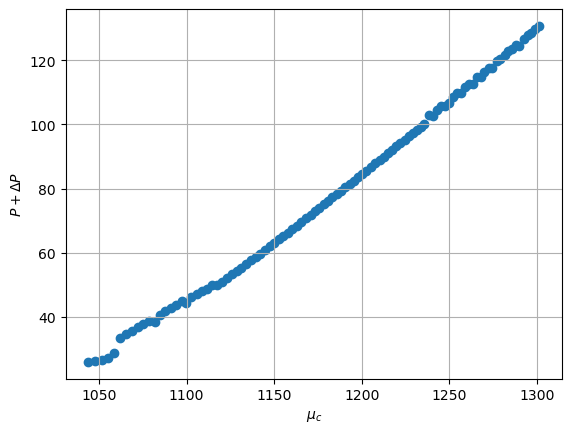

In [32]:
plt.scatter(mu_crit,P_all);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$P + \Delta P $');
plt.show();

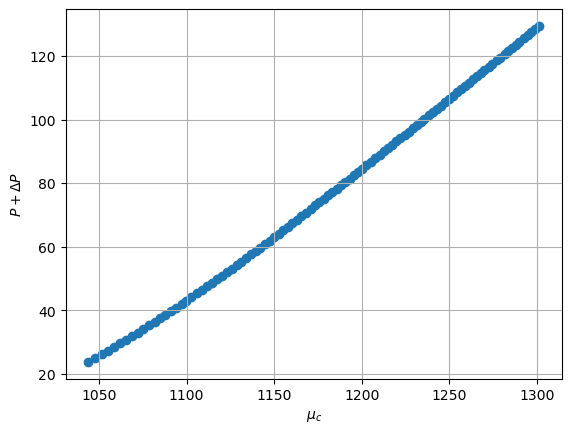

In [33]:
plt.scatter(mu_crit,P_all_1);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$P + \Delta P $');
plt.show();

In [65]:
22/21

1.0476190476190477

In [64]:
P_crit

[21.13985880093062,
 22.119002322209866,
 23.124864293636023,
 23.94895163707452,
 24.861322637111716,
 25.866854734090545,
 26.747846154212443,
 27.646599792715786,
 28.486161528737068,
 29.419288012555956,
 30.29055467866056,
 31.17712249745072,
 31.913939070839778,
 32.828553650155236,
 33.75871761134492,
 34.53138740623783,
 35.49004586932235,
 36.19716713328735,
 37.00270496340783,
 37.91025300082961,
 38.738352662350756,
 39.671084544933265,
 40.426876614104536,
 41.19124285252891,
 41.96421544090091,
 42.94258268731542,
 43.735036604927714,
 44.5362006386513,
 45.24438909298377,
 46.061969892630636,
 46.99226966824536,
 47.82858983108756,
 48.56764293609004,
 49.42061497906043,
 50.17428627888262,
 50.93481199604093,
 51.70221278515583,
 52.47650923898083,
 53.25772188895501,
 54.04587120574759,
 54.840977599794314,
 55.64306142182608,
 56.568298463655395,
 57.385402170522596,
 58.209546881892415,
 58.92157594371096,
 59.758850113006034,
 60.482162603167346,
 61.210702740963484,

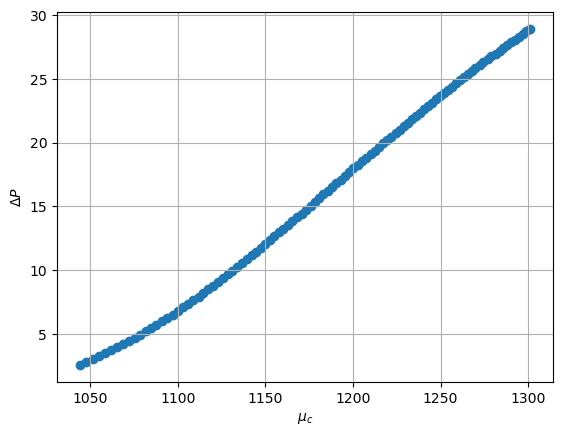

In [34]:
plt.scatter(mu_crit,delta_P_Points);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$\Delta P $');
plt.show();

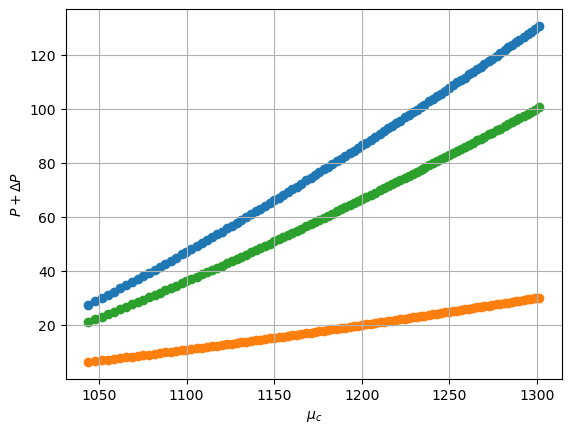

In [47]:
plt.scatter(mu_crit,P_all_max,label=r"$P_crit$");
plt.scatter(mu_crit,delta_P_optimal_max,label=r"$\DeltaP$");
plt.scatter(mu_crit,P_crit,label=r"$P_crit + \Delta P$");
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$P + \Delta P $');
plt.show();

In [36]:
len(delta_P_optimal_max)

100

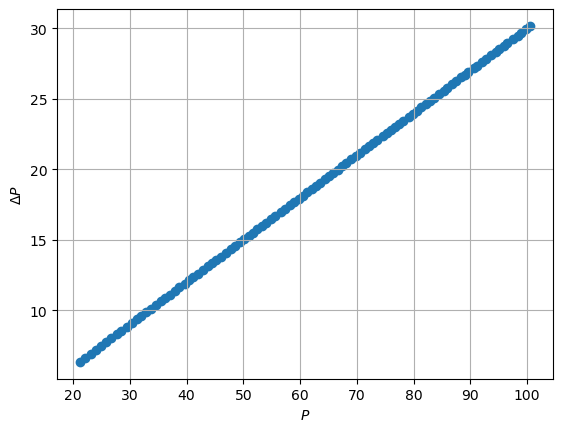

In [45]:
plt.scatter(P_crit,delta_P_optimal_max);
plt.grid();
plt.xlabel(r'$P$');
plt.ylabel(r'$\Delta P $');
plt.show();

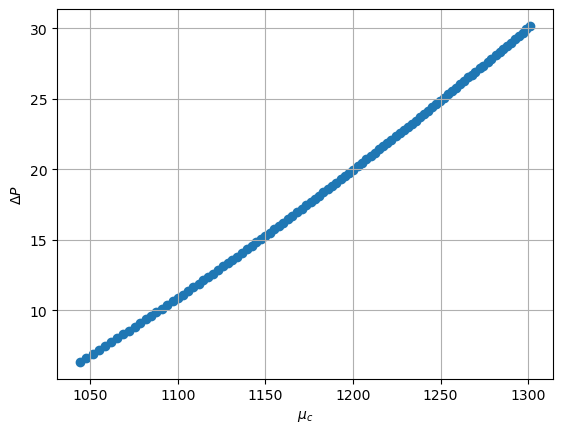

In [37]:
plt.scatter(mu_crit,delta_P_optimal_max);
plt.grid();
plt.xlabel(r'$\mu_c$');
plt.ylabel(r'$\Delta P $');
plt.show();

In [38]:
print(delta_P_Points[0])
print(delta_P_optimal_max[0])
print(P_all[0] - P_crit[0])


2.549479668004125
6.341957640279186
4.734143354298499


In [39]:
(delta_P_Points[0] + delta_P_optimal_max[0])/2

4.445718654141656

In [40]:
print(delta_P_Points[-1])
print(delta_P_optimal_max[-1])
print(P_all[-1] - P_crit[-1])

28.920218930916402
30.17578112869702
30.17578112869704
